# 2005 MDR-TB Thailand: contact evidence and unknown results

**PHI outbreak investigations · 20–30 minutes · original browser companion**

An original PHI-Case-Studies browser companion uses six invented IDs to separate reported contacts, missing laboratory evidence and connected components, while preserving an isolate and avoiding transmission claims.

**Learning question:** Can a weaker reported contact merge components without changing a single observed drug-susceptibility result?

**Data status:** original synthetic teaching fixture; no historical measurements, real patient records, source map or external data requests. This bounded companion runs with standard-library Python and IPython in the atlas Lab. Linked source courses have their own rights and runtimes.


## Predict before running

After the [Cholera sequence](../cholera-1854-advanced-2/index.ipynb), move from geometric rules to evidence joining. Six invented stable IDs carry an observed teaching drug-susceptibility-test (DST) label; `None` means unknown, never susceptible. Undirected reported contacts accept only strong or weak evidence; DST accepts only MDR, non-MDR or None, and unsupported categories stop the calculation. These are invented labels, no patient geography or reconstructed cohort. Predict whether including C–D can merge groups without changing anyone's DST. The component walk follows selected contacts while explicitly preserving every ID, including isolated F.

Write a prediction and an assumption. Run cells in order with **Shift+Enter** or **Run → Run All Cells**. The first code cell supplies local SVG display helpers; the next performs the calculation. Every figure has a title/description and printed values as a text alternative. Allow up to 60 seconds per cell on first runtime load; the fixture calculation normally takes seconds and needs no installs, account or credentials.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Invented observed DST labels: {'A': 'MDR', 'B': 'MDR', 'C': 'unknown', 'D': 'non-MDR', 'E': 'unknown', 'F': 'MDR'}
Selected contact policy: strong only ; components: [['A', 'B', 'C'], ['D', 'E'], ['F']] ; sizes: [3, 2, 1]
MDR / known DST: 3/4 (75.0%); unknown DST / all IDs: 2/6
Fixture summaries are not prevalence. Contact policy never changes observed DST; no directed transmission or clinical inference.


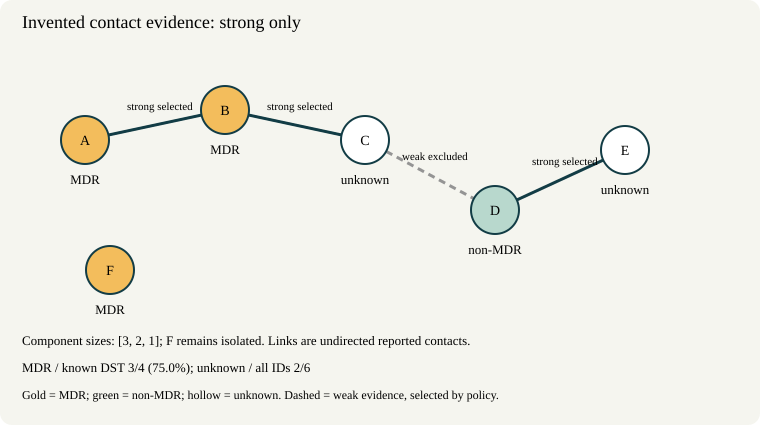

In [2]:
# Invented IDs and observed teaching labels, not historical patient records.
dst = {'A': 'MDR', 'B': 'MDR', 'C': None, 'D': 'non-MDR', 'E': None, 'F': 'MDR'}
contacts = [('A', 'B', 'strong'), ('B', 'C', 'strong'),
            ('C', 'D', 'weak'), ('D', 'E', 'strong')]
include_weak = False

def contact_components(ids, links, use_weak):
    adjacency = {name: set() for name in ids}  # preserves isolated IDs
    for left, right, evidence in links:
        if evidence not in ('strong', 'weak'):
            raise ValueError('Contact evidence must be strong or weak')
        if evidence == 'strong' or (evidence == 'weak' and use_weak):
            adjacency[left].add(right)
            adjacency[right].add(left)
    remaining = set(ids)
    components = []
    while remaining:
        todo = [min(remaining)]; group = set()
        while todo:
            name = todo.pop()
            if name in group:
                continue
            group.add(name)
            todo.extend(adjacency[name] - group)
        remaining -= group
        components.append(sorted(group))
    return sorted(components, key=lambda group: (-len(group), group))

def dst_summary(labels):
    if any(value not in ('MDR', 'non-MDR', None) for value in labels.values()):
        raise ValueError('DST labels must be MDR, non-MDR or None')
    known = sum(value in ('MDR', 'non-MDR') for value in labels.values())
    mdr = sum(value == 'MDR' for value in labels.values())
    return {'mdr': mdr, 'known': known, 'unknown': len(labels)-known,
            'fraction': mdr/known if known else None}

components = contact_components(dst, contacts, include_weak)
sizes = [len(group) for group in components]
summary = dst_summary(dst)
fraction_label = 'unknown' if summary['fraction'] is None else f'{summary["fraction"]:.1%}'
policy = 'strong + weak' if include_weak else 'strong only'
print('Invented observed DST labels:', {name: ('unknown' if value is None else value) for name, value in dst.items()})
print('Selected contact policy:', policy, '; components:', components, '; sizes:', sizes)
print(f'MDR / known DST: {summary["mdr"]}/{summary["known"]} ({fraction_label}); unknown DST / all IDs: {summary["unknown"]}/{len(dst)}')
print('Fixture summaries are not prevalence. Contact policy never changes observed DST; no directed transmission or clinical inference.')

coordinates = {'A': (85, 140), 'B': (225, 110), 'C': (365, 140),
               'D': (495, 210), 'E': (625, 150), 'F': (110, 270)}
body = f'<text x="22" y="28" font-size="18">Invented contact evidence: {escape(policy)}</text>'
for left, right, evidence in contacts:
    x1, y1 = coordinates[left]; x2, y2 = coordinates[right]
    selected = evidence == 'strong' or (evidence == 'weak' and include_weak)
    color = '#123c45' if selected else '#949494'
    dash = ' stroke-dasharray="7 5"' if evidence == 'weak' else ''
    body += f'<path d="M{x1} {y1}L{x2} {y2}" stroke="{color}" stroke-width="3"{dash}/>'
    label = evidence + (' selected' if selected else ' excluded')
    body += f'<text x="{(x1+x2)/2-28}" y="{(y1+y2)/2-15}" font-size="11">{escape(label)}</text>'
for name, value in dst.items():
    x, y = coordinates[name]
    fill = '#f3bd5c' if value == 'MDR' else '#b8d8cd' if value == 'non-MDR' else '#ffffff'
    label = 'unknown' if value is None else value
    body += f'<circle cx="{x}" cy="{y}" r="24" fill="{fill}" stroke="#123c45" stroke-width="2"/>'
    body += f'<text x="{x}" y="{y+5}" text-anchor="middle" font-size="14">{escape(name)}</text><text x="{x}" y="{y+44}" text-anchor="middle" font-size="13">{escape(label)}</text>'
body += f'<text x="22" y="345" font-size="13">Component sizes: {escape(str(sizes))}; F remains isolated. Links are undirected reported contacts.</text>'
body += f'<text x="22" y="372" font-size="13">MDR / known DST {summary["mdr"]}/{summary["known"]} ({fraction_label}); unknown / all IDs {summary["unknown"]}/{len(dst)}</text>'
body += '<text x="22" y="399" font-size="12">Gold = MDR; green = non-MDR; hollow = unknown. Dashed = weak evidence, selected by policy.</text>'
description = f'Six invented IDs. Contact policy {policy}; component sizes {sizes}. MDR {summary["mdr"]} of {summary["known"]} known DST ({fraction_label}); unknown {summary["unknown"]} of {len(dst)} IDs. ' + '; '.join(f'{name}: {"unknown" if value is None else value}' for name, value in dst.items())
svg(body, 'Synthetic MDR-TB: contacts and observed DST', description, height=425)


## Interpret the result

Strong-only contacts produce **ABC / DE / F**, component sizes **3 / 2 / 1**. Observed labels give **3 MDR / 4 known DST**, and **2 unknown / 6 total IDs**. The first denominator excludes unknowns; the second includes everyone. Neither fraction is prevalence in a real population. Gold, green and hollow nodes represent MDR, non-MDR and unknown; line style represents evidence policy. There are no arrows because neither temporal direction nor transmission is established. Contact, component membership, genotype similarity and laboratory resistance are different evidence types.

## Change one thing

Set `include_weak = True`: components become **ABCDE / F**, sizes **5 / 1**, while every observed DST label stays the same. Restore `False`, then change only `'C': None` to `'C': 'MDR'`: **4 / 5 known DST**, with one unknown among six IDs. Finally set all DST values to `None`: the fraction must be **unknown**, not 0%, while components still follow contact policy. Restore defaults and draft a record-joining check: stable ID, duplicate-edge handling, missing lab result, interview confidence and who may access sensitive evidence.

Save your edited experiment with **File → Save and Export Notebook As → Notebook** or the file browser's Download command. Browser storage belongs to this browser/profile; it is not a GitHub commit or a shared patient database. Restart the kernel and Run All to check your saved version.


## Put the method in context

The 2005 investigation concerned US-bound Hmong refugees in Thailand. Read Oeltmann and colleagues' 2008 article with respect for people navigating displacement and access barriers; the historical setting does not justify stigmatizing a community. The source course moves through investigation/genotyping, historical WHO/World Bank country-year preparation and merges, Plotly ecological summaries, genotype/DST joins, secondary interviews and social networks. The contact lesson is marked work in progress. Country-level TB/GDP/education/spending summaries do not identify individual risk or mechanisms. Historical source data and policies are not current clinical or immigration guidance, and no historical API is called here. An actual diagnosis requires laboratory/clinical evidence; this exercise supplies none.


## 2005 MDR-TB Thailand: contact evidence and unknown results: inspected source notebooks

**Creators:** PHI-Case-Studies and contributors as teaching-course creators, with John Oeltmann credited in the source. Research authors are credited separately below.

**Repository:** [PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand). [Reviewed README](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/README.md), full commit `6d50f558cd39b40089cd3eea1fbc19425e5191d1`, branch `master`, inspected 2026-11-02.

The source documents Binder/native Notebook, not a deployed JupyterLite course; no public JupyterLite counterpart was found. Its pandas, Plotly, NetworkX and Bokeh pipeline is separate. A Binder entry response is not a running session; no Binder build was started.

**Source rights:** Root LICENSE: Apache 2.0.

| Inspected source file | What the source teaches |
|---|---|
| [NB01-MDR-TB-Case-Study-Case-Intro.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB01-MDR-TB-Case-Study-Case-Intro.ipynb) | Investigation, genotyping and the information workflow |
| [NB02-World-TB-Notebook-Part-1.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB02-World-TB-Notebook-Part-1.ipynb) | Historical WHO/World Bank TB, GDP, education and health-spending preparation |
| [NB03-World-TB-Notebook-Part-2.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB03-World-TB-Notebook-Part-2.ipynb) | Country/year data merging |
| [NB04-World-TB-Notebook-Part-3.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB04-World-TB-Notebook-Part-3.ipynb) | Plotly exploration and ecological summaries |
| [NB05-MDR-TB-Case-Study-Part-1.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB05-MDR-TB-Case-Study-Part-1.ipynb) | Mapping and genotype/DST joins |
| [NB06-MDR-TB-Case-Study-Part-2.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB06-MDR-TB-Case-Study-Part-2.ipynb) | Reported contacts, duplicate edges and secondary interviews; work in progress |
| [NB07-MDR-TB-Case-Study-Part-3.ipynb](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/NB07-MDR-TB-Case-Study-Part-3.ipynb) | Social networks with NetworkX/Bokeh |

[Root license at the inspected commit](https://github.com/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/blob/6d50f558cd39b40089cd3eea1fbc19425e5191d1/LICENSE).

**Historical provider pipeline:** WHO and the World Bank are credited as providers in the pinned NB02–NB04 preparation/merge/exploration sequence. The inspected source snapshot is dated 2025-07-23; its preserved country/year TB, GDP, education and health-spending inputs are historical course material. No current provider feed is queried, no source table is imported, and country-level associations cannot identify individual risk. Provider attribution here is through those inspected source notebooks, rather than a claim to have refreshed their underlying datasets.


## Source launch resources and runtime limits

- [Source Binder entry (native/server)](https://beta.mybinder.org/v2/gh/PHI-Case-Studies/2005-MDR-TB-Outbreak-Thailand/master) — Exact README-documented Binder entry; no build/session started. Native/server continuation, not JupyterLite. **HTTP 200 - entry only; no Binder build; checked 2026-11-02.**

These dated GET checks establish entry reachability only. The Basic/Advanced1 notebook filenames were also present in published manifests; no source execution, widget, tile/provider behavior or Binder session is certified. No Binder build is triggered by these atlas activities. Source continuation may require packages, networking and provider terms absent from the default atlas runtime.


## Sources, attribution and use

- **Oeltmann, J. E.; Varma, J. K.; Ortega, L.; Liu, Y.; O'Rourke, T.; Cano, M.; et al. (2008).** *Multidrug-Resistant Tuberculosis Outbreak among US-bound Hmong Refugees, Thailand, 2005.* Emerging Infectious Diseases **14**(11), 1715–1721. [DOI](https://doi.org/10.3201/eid1411.071629), [primary article](https://wwwnc.cdc.gov/eid/article/14/11/07-1629_article). Credit the research authors, CDC, Thailand Ministry of Public Health and International Organization for Migration. Published tables, patient locations, networks and effect estimates are not reproduced in the atlas.
- **World Health Organization (20 May 2024).** [*Tuberculosis: Multidrug-resistant (MDR-TB) or rifampicin-resistant TB (RR-TB)*](https://www.who.int/news-room/questions-and-answers/item/tuberculosis-multidrug-resistant-tuberculosis-%28mdr-tb%29). MDR includes resistance to rifampicin and isoniazid; this exercise computes no diagnosis or treatment decision. Historical policies/data are not current clinical or immigration guidance.

- **NetworkX contributors.** [Weighted shortest paths](https://networkx.org/documentation/stable/reference/algorithms/shortest_paths.html) and [connected components](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.components.connected_components.html), algorithm background only. No NetworkX code/examples are copied and no package installation is needed.
- **SciPy contributors.** [Voronoi method documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Voronoi.html), source-method context only. The atlas samples a finite nearest-site grid rather than constructing exact Voronoi polygons; SciPy is not installed by these activities.
- **OpenStreetMap contributors.** [Copyright and ODbL attribution](https://www.openstreetmap.org/copyright). Source streets/buildings and Folium/CARTO tiles have separate data/provider terms. All atlas geometry is invented; no OSM graph, footprint, tile or historical basemap is bundled or downloaded. Retain required attribution in source continuations.
- **Upstream software communities:** pandas, NumPy, Folium, OSMnx, NetworkX, GeoPandas, Shapely, SciPy, Bokeh and Plotly support the linked source courses. The original atlas activities execute only Python's standard library and IPython display, under the atlas's existing runtime notices.

All summaries, code, synthetic fixtures and SVGs here are newly authored: MIT executable code; CC BY 4.0 narrative, fixtures and figures, James L. Tobias and JupyterLite Learning Atlas contributors (2026). No source code/prose/data/imagery, patient records, pickles, saved graphs or map tiles are copied. Source rights remain with their creators; public access and shared contributors imply no blanket relicensing or endorsement.

[Central references](../../references.ipynb) · [Visual provenance](../../visual-provenance.ipynb)


## Continue the investigation

Basic → Advanced1 → Advanced2 → MDR-TB is the suggested order.

[1854 Cholera Basic: dots, counts and centres](../cholera-1854-basic/index.ipynb) · [1854 Cholera Advanced1: routes and reachable nodes](../cholera-1854-advanced-1/index.ipynb) · [1854 Cholera Advanced2: nearest sites, ties and buildings](../cholera-1854-advanced-2/index.ipynb)

[Browser Python](../../foundations/browser-python.ipynb) · [Spatial thinking](../../foundations/spatial-thinking.ipynb) · [Global-health synthesis](../../synthesis/global-health.ipynb) · [Learning routes](../../index.ipynb)
